In [1]:
import sys

print("My electricity forecasting project")
print("Python version:", sys.version.split()[0])
print("Colab is ready!")

My electricity forecasting project
Python version: 3.13.18
Colab is ready!


In [3]:
import pandas as pd  # Use the short name "pd" for pandas

url = "https://raw.githubusercontent.com/jenfly/opsd/master/opsd_germany_daily.csv"

# Load only the two columns we need
df = pd.read_csv(url, usecols=["Date", "Consumption"])

print(df.head())  # Show the first 5 rows
print("Rows and columns:", df.shape)

         Date  Consumption
0  2006-01-01     1069.184
1  2006-01-02     1380.521
2  2006-01-03     1442.533
3  2006-01-04     1457.217
4  2006-01-05     1477.131
Rows and columns: (4383, 2)


In [4]:
# Convert the Date column from text to dates
df["Date"] = pd.to_datetime(df["Date"])

# Arrange the rows from oldest to newest
df = df.sort_values("Date").reset_index(drop=True)

print("Column types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate dates:", df["Date"].duplicated().sum())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Column types:
Date           datetime64[ns]
Consumption           float64
dtype: object

Missing values:
Date           0
Consumption    0
dtype: int64

Duplicate dates: 0
Date range: 2006-01-01 00:00:00 to 2017-12-31 00:00:00


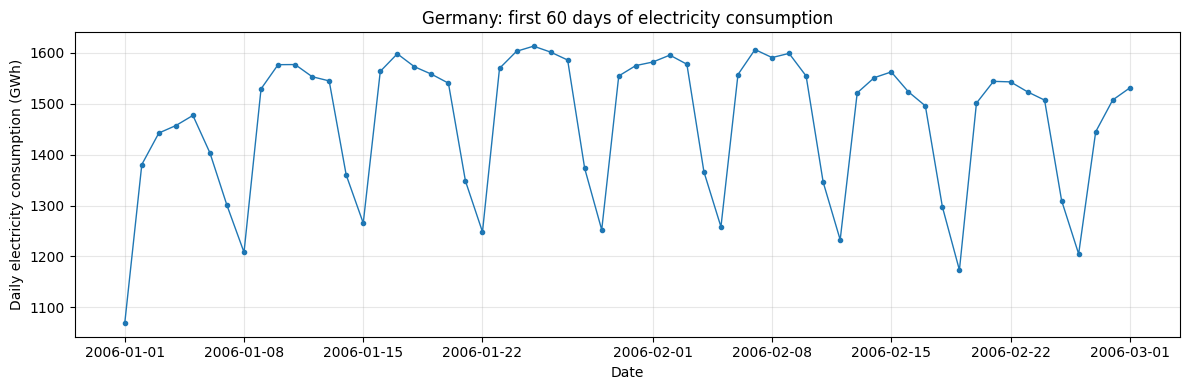

In [5]:
import matplotlib.pyplot as plt  # Library for drawing graphs

sample = df.head(60)  # Select the first 60 days

plt.figure(figsize=(12, 4))
plt.plot(sample["Date"], sample["Consumption"], marker=".", linewidth=1)
plt.title("Germany: first 60 days of electricity consumption")
plt.xlabel("Date")
plt.ylabel("Daily electricity consumption (GWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
train = df[df["Date"] < "2017-01-01"].copy()
test = df[df["Date"] >= "2017-01-01"].copy()

print("Training rows:", len(train))
print("Training dates:", train["Date"].min(), "to", train["Date"].max())

print("\nTest rows:", len(test))
print("Test dates:", test["Date"].min(), "to", test["Date"].max())

Training rows: 4018
Training dates: 2006-01-01 00:00:00 to 2016-12-31 00:00:00

Test rows: 365
Test dates: 2017-01-01 00:00:00 to 2017-12-31 00:00:00


In [7]:
# Align consumption from 7 days earlier with each test date
test["Baseline"] = df["Consumption"].shift(7).loc[test.index]

# Calculate errors without allowing negatives to cancel positives
errors = (test["Consumption"] - test["Baseline"]).abs()

print("Baseline MAE (GWh):", round(errors.mean(), 2))
print(test[["Date", "Consumption", "Baseline"]].head())

Baseline MAE (GWh): 54.1
           Date  Consumption  Baseline
4018 2017-01-01     1130.413  1117.673
4019 2017-01-02     1441.052  1121.213
4020 2017-01-03     1529.990  1289.324
4021 2017-01-04     1553.083  1294.881
4022 2017-01-05     1547.238  1295.897


In [8]:
baseline_mae = errors.mean()  # Keep our baseline score

model_data = df.copy()

model_data["lag_1"] = model_data["Consumption"].shift(1)
model_data["lag_7"] = model_data["Consumption"].shift(7)

model_data["day_of_week"] = model_data["Date"].dt.dayofweek
model_data["month"] = model_data["Date"].dt.month

print(model_data.head(10))

        Date  Consumption     lag_1     lag_7  day_of_week  month
0 2006-01-01     1069.184       NaN       NaN            6      1
1 2006-01-02     1380.521  1069.184       NaN            0      1
2 2006-01-03     1442.533  1380.521       NaN            1      1
3 2006-01-04     1457.217  1442.533       NaN            2      1
4 2006-01-05     1477.131  1457.217       NaN            3      1
5 2006-01-06     1403.427  1477.131       NaN            4      1
6 2006-01-07     1300.287  1403.427       NaN            5      1
7 2006-01-08     1207.985  1300.287  1069.184            6      1
8 2006-01-09     1529.323  1207.985  1380.521            0      1
9 2006-01-10     1576.911  1529.323  1442.533            1      1


In [9]:
features = ["lag_1", "lag_7", "day_of_week", "month"]

model_data = model_data.dropna(subset=features + ["Consumption"])

train = model_data[model_data["Date"] < "2017-01-01"].copy()
test = model_data[model_data["Date"] >= "2017-01-01"].copy()

X_train = train[features]
y_train = train["Consumption"]

X_test = test[features]
y_test = test["Consumption"]

print("Training inputs (rows, columns):", X_train.shape)
print("Test inputs (rows, columns):", X_test.shape)

Training inputs (rows, columns): (4011, 4)
Test inputs (rows, columns): (365, 4)


In [10]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,  # Build 200 trees
    max_depth=10,     # Limit each tree's complexity
    random_state=42   # Make the randomness reproducible
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Training complete!")
print("First 5 predictions (GWh):", predictions[:5].round(2))

Training complete!
First 5 predictions (GWh): [1129.04 1396.74 1461.08 1546.09 1563.02]


In [11]:
model_mae = (y_test - predictions).abs().mean()

mae_reduction = 100 * (baseline_mae - model_mae) / baseline_mae

print("Weekly baseline MAE (GWh):", round(baseline_mae, 2))
print("Random Forest MAE (GWh):", round(model_mae, 2))
print("MAE reduction vs baseline (%):", round(mae_reduction, 2))

Weekly baseline MAE (GWh): 54.1
Random Forest MAE (GWh): 25.42
MAE reduction vs baseline (%): 53.02


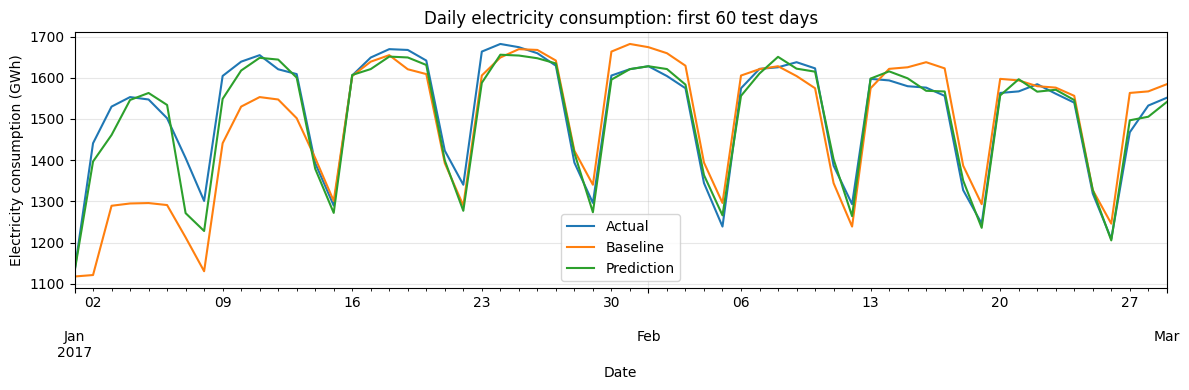

In [12]:
results = test[["Date", "Consumption", "lag_7"]].copy()
results.columns = ["Date", "Actual", "Baseline"]
results["Prediction"] = predictions

results.head(60).plot(x="Date", figsize=(12, 4))
plt.title("Daily electricity consumption: first 60 test days")
plt.ylabel("Electricity consumption (GWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
results["Error"] = results["Actual"] - results["Prediction"]
results["Absolute_error"] = results["Error"].abs()

worst_days = results.sort_values(
    "Absolute_error", ascending=False
).head(5)

columns = ["Date", "Actual", "Prediction", "Error", "Absolute_error"]
print(worst_days[columns].round(2).to_string(index=False))

      Date  Actual  Prediction   Error  Absolute_error
2017-05-01 1103.22     1417.86 -314.63          314.63
2017-12-25 1111.28     1387.87 -276.59          276.59
2017-05-25 1094.20     1365.63 -271.43          271.43
2017-04-17 1086.46     1340.05 -253.60          253.60
2017-04-14 1130.28     1368.86 -238.58          238.58


In [14]:
next_date = df["Date"].iloc[-1] + pd.Timedelta(days=1)

next_inputs = pd.DataFrame([{
    "lag_1": df["Consumption"].iloc[-1],
    "lag_7": df["Consumption"].iloc[-7],
    "day_of_week": next_date.dayofweek,
    "month": next_date.month
}], columns=features)

next_prediction = model.predict(next_inputs)[0]

print("Forecast date:", next_date.date())
print(next_inputs)
print("Predicted consumption (GWh):", round(next_prediction, 2))

Forecast date: 2018-01-01
        lag_1       lag_7  day_of_week  month
0  1107.11488  1111.28338            0      1
Predicted consumption (GWh): 1390.14


In [16]:
import joblib
from pathlib import Path
from importlib.metadata import version
from google.colab import drive

drive.mount("/content/drive")

folder = Path("/content/drive/MyDrive/Electricity_Forecasting")
folder.mkdir(parents=True, exist_ok=True)

bundle = {"model": model, "features": features,
          "baseline_mae": baseline_mae, "model_mae": model_mae}
joblib.dump(bundle, folder / "forecast_model.joblib")
results.to_csv(folder / "test_predictions.csv", index=False)
df.to_csv(folder / "source_data.csv", index=False)

packages = ["pandas", "numpy", "scipy", "scikit-learn", "joblib"]
requirements = "\n".join(f"{p}=={version(p)}" for p in packages)
(folder / "requirements.txt").write_text(requirements)

print("Saved files:", sorted(p.name for p in folder.iterdir()))

Mounted at /content/drive
Saved files: ['forecast_model.joblib', 'requirements.txt', 'source_data.csv', 'test_predictions.csv']


## Limitations

- Evaluation covers daily, one-day-ahead forecasts during 2017.
- Each prediction uses earlier actual consumption readings as they become available.
- The five largest errors occurred on public holidays. The model has no explicit holiday feature.
- Performance on other years or countries has not been tested.
